# Transfer learning under distribution shifts and heterogeneous feature spaces

This notebook accompanies the simulation study in Section 5 of the paper. We compare source-pretrained and target-only FT–MDN–Transformer (FT–MDN–T) models on the same target observations. The design varies the distribution shift, the predictors available in each domain and the number of labeled target recoveries.

Select a mode in the first code cell, then choose **Run All**.

| Mode | Execution |
|---|---|
| `review` (default) | Uses the saved simulation runs, rescores 60 sets of density forecasts and regenerates the tables and figures. |
| `rebuild` | Generates synthetic data and fits or resumes the experiments in `outputs/simulation_rebuild`. The validation study takes the longest to run. |

Run the notebook from the repository root or the notebooks directory. The reference runs used Python 3.9.19 on CPU with one Torch thread. [Dependencies](../requirements.txt) · [Generator configuration](../configs/simulation/source_data_config_categories.yaml)

### Figures and tables

| Paper item | Notebook section | Output |
|---|---|---|
| Figure 11 · Transfer gains across shifts and schemas | 1 | `paired_gain_r2.pdf` |
| Figure 12 · Sensitivity to target training duration | 2 | `training_sensitivity.pdf` |
| Figure 13 · Point and density forecasts at three target sizes | 3 | `three_budget_forecasts.pdf` |
| Online appendix, Figure 1 · Synthetic source and target domains | 1 | `generator_diagnostics.pdf` |
| Online appendix, Figures 2–3 · Absolute performance and feature-augmented ridge | 4 | `absolute_r2.pdf`, `augmentation_r2.pdf` |
| Online appendix, Table 1 · Point and density scores | 3 | Scores by model and target size |
| Online appendix, Figure 4 · Validation results across target sample sizes | 5 | `transfer_vs_target_size_reconstruction.pdf` |

The manuscript figure filenames carry the prefix `revision_`. The [repository guide](../README.md#where-to-find-each-paper-result) also lists the empirical figures.

In [26]:
MODE = "review"  # review | rebuild
from itertools import product
from pathlib import Path
import os, sys, subprocess
import pandas as pd
import torch
import warnings
# Pandas 1.4 announces a future LaTeX API change once for each table export.
warnings.filterwarnings("ignore", message=r"In future versions .*DataFrame.to_latex.*",
                        category=FutureWarning, module=r"simulation\.(paper_results|augmentation)")
from IPython.display import display, FileLink
root = Path.cwd().resolve()
repo = root if (root / "src/simulation").is_dir() else root.parent
if MODE not in {"review","rebuild"} or not (repo/"src/simulation").is_dir():
    raise ValueError("Select a documented mode and start in Code Repository or notebooks.")
sys.path.insert(0,str(repo/"src"))
from simulation.notebook_reporting import quiet_epochs, rebuild_panel, show_figure
from simulation.paper_results import export
from simulation.figure_inventory import plot_generator, plot_historical, plot_augmentation
from simulation.augmentation import augmentation_panel
from simulation import density_confirmation as dc
torch.set_num_threads(1)
config = repo/"configs/simulation/source_data_config_categories.yaml"
outputs = repo/"outputs"
if MODE == "rebuild":
    outputs = outputs/"simulation_rebuild"
paper = outputs/"simulation_paper"
primary, longer = outputs/"simulation_revision_v1", outputs/"simulation_sensitivity_80"
final, historical = paper/"final", paper/"historical"
raw_root = outputs/"historical_replay"
print(f"Mode {MODE} | Python {sys.version.split()[0]} | Torch {torch.__version__} | output {outputs.relative_to(repo)}")

Mode review | Python 3.9.19 | Torch 2.6.0 | output outputs


## 1. Transfer gains across shifts and feature schemas

The main experiment combines four regimes (no shift, covariate shift, label shift and conditional shift) with three feature schemas (equal predictors, fewer source predictors or fewer target predictors). Each target sample contains 100 or 500 labels, including those reserved for validation.

Within each of five replications, both FT–MDN–T models use the same target fitting, validation and assessment observations. The scratch model trains on target data alone. The pretrained model first trains on the source and then adapts to the target. We express transfer gains as the increase in assessment R² or the reduction in MAE.

,gain_r2,gain_mae
budget,,
100,0.581035,0.092692
500,0.243238,0.046282


../outputs/simulation_paper/final/generator_diagnostics.pdf

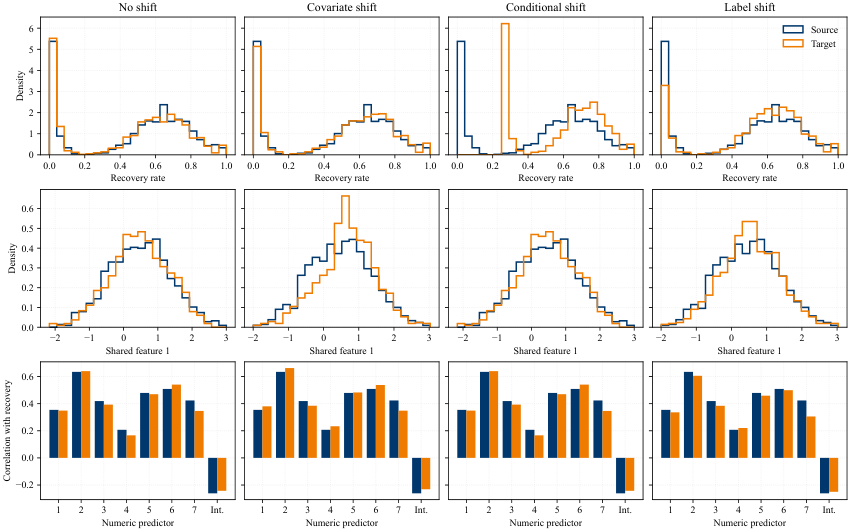

../outputs/simulation_paper/final/paired_gain_r2.pdf

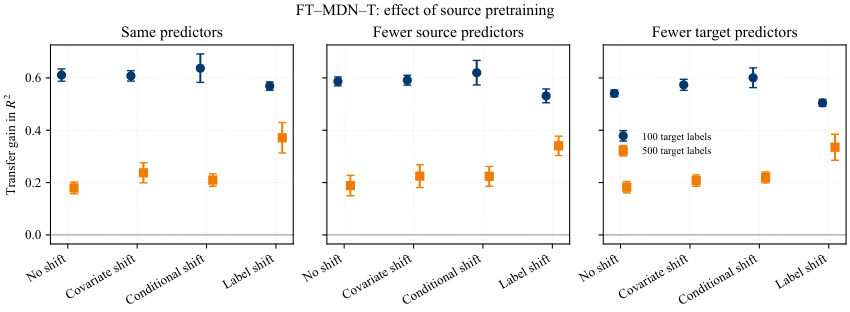

In [29]:
if MODE == "rebuild":
    rebuild_panel(config, primary, 20)
    rebuild_panel(config, longer, 80)
table = export(config, primary, final, sensitivity=longer)
display(table.groupby("budget")[["gain_r2","gain_mae"]].mean())
plot_generator(config, final)
show_figure(final/"generator_diagnostics.pdf")
show_figure(final/"paired_gain_r2.pdf")

## 2. Sensitivity to target training duration

We increase the target training cap from 20 to 80 epochs for both models, using the same simulated draws. This comparison covers the no-shift and label-shift regimes, each with equal schemas or fewer target predictors. We average the four paired gains within each replication, then calculate the Monte Carlo standard error (MCSE) across replications.

,mean,MCSE
gain_r2_80,0.313337,0.026872
gain_mae_80,0.051519,0.005877


,gain_r2_20,gain_r2_80,gain_mae_80
budget,,,
100,0.556,0.333,0.057
500,0.267,0.020,0.005


,both_improved_80,scratch_at_cap_80
budget,,
100,20,8
500,15,4


../outputs/simulation_paper/final/training_sensitivity.pdf

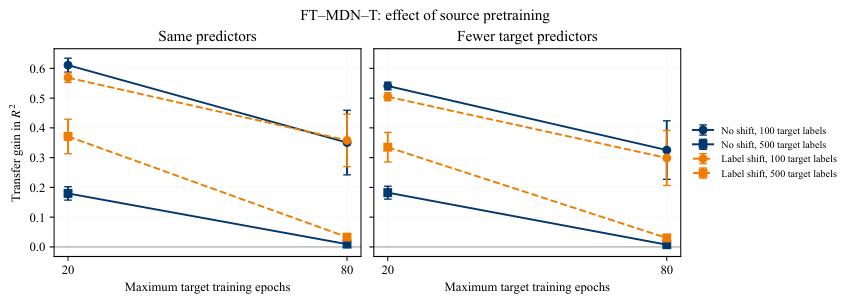

../outputs/simulation_paper/final/sensitivity.csv

In [31]:
pairs = pd.read_csv(final / "sensitivity_pairs.csv")
metrics = ["gain_r2_80", "gain_mae_80"]
by_seed = pairs.groupby(["rep", "budget"])[metrics].mean()
contrast = by_seed.xs(100, level="budget") - by_seed.xs(500, level="budget")
display(pd.DataFrame({"mean": contrast.mean(), "MCSE": contrast.sem()}))

pairs["both_improved_80"] = (pairs.gain_r2_80>0) & (pairs.gain_mae_80>0)
display(pairs.groupby("budget")[["gain_r2_20","gain_r2_80","gain_mae_80"]].mean().round(3))
display(pairs.groupby("budget")[["both_improved_80","scratch_at_cap_80"]].sum())
show_figure(final/"training_sensitivity.pdf")
display(FileLink(os.path.relpath(final/"sensitivity.csv")))

## 3. Point and density forecasts at 100, 250 and 500 target labels

Five new replications cover the four settings in Section 2. Both FT–MDN–T models train for up to 160 target epochs, with checkpoint selection by validation R². The original comparison used 100 and 500 labels. After examining those results, we added 250 labels using the same seeds, target distributions and assessment observations. Training samples across the three budgets need not be nested.

We assess the predicted recovery distributions using CRPS and negative log likelihood (NLL), both of which favor lower scores. Gaussian ridge regression provides a conditional density benchmark. For the central 80% prediction intervals, we report empirical coverage and mean width.

In [35]:
import hashlib
density_root = outputs/"simulation_density_confirmation"
if MODE == "rebuild":
    with quiet_epochs():
        confirmation = dc.run(config,density_root)
else:
    confirmation = density_root/"cd51b94bd7c3"
protocol = confirmation/"protocol.json"
if not protocol.is_file() or hashlib.sha256(protocol.read_bytes()).hexdigest()[:12] != confirmation.name:
    raise ValueError(f"Missing or inconsistent density protocol: {protocol}. Restore the archive or use rebuild.")
expected = {f"{r}-{s}-{h}-{b}.npz" for r,s,h,b in product(dc.REPS,dc.SCHEMAS,dc.SHIFTS,dc.BUDGETS)}
available = {p.name for p in confirmation.glob("*.npz")}
if available != expected:
    raise ValueError(f"Density archive mismatch. Missing: {sorted(expected-available)}. Unexpected: {sorted(available-expected)}.")
print(f"Density assessment | {len(expected)} paired cases | protocol {confirmation.name}")
with quiet_epochs():
    learning_curve = dc.midpoint(config, confirmation, outputs/"simulation_density_midpoint",
                                 fit=MODE=="rebuild")
if learning_curve is None:
    raise FileNotFoundError("Restore the archived 250-label forecasts or select rebuild.")

mid_root = outputs/"simulation_density_midpoint"
mid_run = (dc._folder(config, mid_root, (250,)) if MODE == "rebuild"
           else mid_root/"7103cc9b0f9a")
scores = pd.concat([pd.read_csv(folder/"absolute_scores.csv") for folder in (confirmation,mid_run)])
absolute = scores.groupby(["budget","arm"])[["R2","MAE","CRPS","NLL","coverage80","width80"]].mean()
print("Mean assessment scores for each model")
display(absolute.round(4))
print("Paired gain from pretraining and MCSE across five replication averages")
display(learning_curve.round(4))

Density assessment | 40 paired cases | protocol cd51b94bd7c3
Mean assessment scores for each model


R2     MAE    CRPS     NLL  coverage80  width80
budget arm                                                          
100    ridge     0.5527  0.1591  0.1126 -0.1682      0.7842   0.5053
       scratch   0.2972  0.2008  0.1474  0.0452      0.8417   0.8698
       transfer  0.5361  0.1640  0.1086 -0.3123      0.8294   0.5362
250    ridge     0.5994  0.1488  0.1055 -0.2503      0.7738   0.4530
       scratch   0.5304  0.1580  0.1089 -0.3870      0.7824   0.5341
       transfer  0.5724  0.1538  0.1014 -0.4574      0.8017   0.4706
500    ridge     0.6077  0.1469  0.1043 -0.2671      0.7947   0.4682
       scratch   0.5938  0.1447  0.0959 -0.5738      0.7722   0.4166
       transfer  0.6001  0.1454  0.0950 -0.5881      0.7881   0.4294

Paired gain from pretraining and MCSE across five replication averages


CRPS              R2             MAE             NLL        
          mean     sem    mean     sem    mean     sem    mean     sem
budget                                                                
100     0.0388  0.0105  0.2389  0.0418  0.0368  0.0061  0.3575  0.0970
250     0.0075  0.0050  0.0421  0.0220  0.0042  0.0026  0.0703  0.0426
500     0.0008  0.0009  0.0063  0.0053 -0.0006  0.0010  0.0143  0.0276

../outputs/simulation_paper/final/three_budget_forecasts.pdf

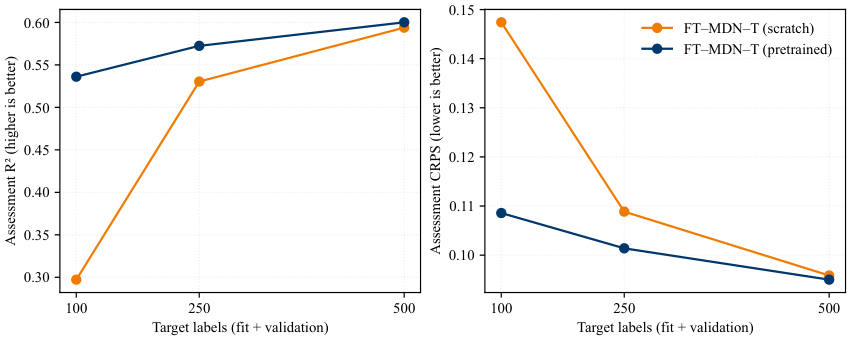

In [36]:
from simulation.paper_results import PAPER_STYLE, BLUE, ORANGE
import matplotlib.pyplot as plt
with plt.rc_context(PAPER_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), constrained_layout=True)
    for ax, metric in zip(axes, ("R2", "CRPS")):
        for arm, color, label in (("scratch", ORANGE, "FT–MDN–T (scratch)"), ("transfer", BLUE, "FT–MDN–T (pretrained)")):
            series = absolute.xs(arm, level="arm")[metric]
            ax.plot(series.index, series.values, marker="o", color=color, label=label)
        ax.set(xlabel="Target labels (fit + validation)", xticks=[100, 250, 500],
               ylabel="Assessment R² (higher is better)" if metric=="R2" else "Assessment CRPS (lower is better)")
    axes[1].legend()
    fig.savefig(final/"three_budget_forecasts.pdf", metadata={"CreationDate":None})
    plt.close(fig)
show_figure(final/"three_budget_forecasts.pdf")

In the saved runs, mean assessment R² for pretrained FT–MDN–T rose from 0.536 at 100 labels to 0.572 at 250 and 0.600 at 500. The target-only model improved more over this range. The corresponding mean gains from pretraining were 0.239, 0.042 and 0.006 (MCSE 0.022 at 250 labels). The gain diminished across these settings, although the three sample sizes do not establish a cutoff. Gaussian ridge achieved the highest mean R² at each budget. Pretrained FT–MDN–T achieved the lowest mean CRPS and NLL at all three.

The table below reports the difference in transfer gain between 100 and 500 labels. Positive values indicate a larger gain at 100 labels. The training summaries distinguish runs that reached the epoch cap from runs in which validation selected the final epoch.

In [38]:
display(dc.summarize(confirmation).round(4))
ft_scores = scores.loc[scores.arm != "ridge"].copy()
ft_scores["ran_to_cap"] = ft_scores.epochs_run.eq(dc.CAP)
ft_scores["selected_cap"] = ft_scores.selected_epoch.eq(dc.CAP)
display(ft_scores.groupby(["budget","arm"])[["ran_to_cap","selected_cap"]].sum())
display(FileLink(os.path.relpath(mid_run/"three_budget_by_rep.csv")))
display(FileLink(os.path.relpath(confirmation/"scarcity_contrast_by_rep.csv")))

,mean,MCSE
CRPS,0.0380,0.0108
R2,0.2326,0.0465
MAE,0.0375,0.0065
NLL,0.3432,0.1032


ran_to_cap  selected_cap
budget arm                               
100    scratch            3             1
       transfer           0             0
250    scratch            5             0
       transfer           0             0
500    scratch            1             0
       transfer           0             0

../outputs/simulation_density_midpoint/7103cc9b0f9a/three_budget_by_rep.csv

../outputs/simulation_density_confirmation/cd51b94bd7c3/scarcity_contrast_by_rep.csv

## 4. Model comparisons across feature schemas

Using the main 20-epoch experiment, we compare FT–MDN–T with target-only XGBoost, XGBoost with a target residual correction, and ridge regression with shared and domain-specific coefficients. The figures report assessment R² within each shift and schema. The final comparison gives both absolute R² and the gain over scratch training under no shift and label shift.

budget,100,500
schema,,
equal,-0.046464,-0.036886
source_subset,-0.044659,-0.044451
target_subset,0.016182,0.003293


,FT_above_both_trees,FT_above_augmented_ridge
budget,,
100,10,3
500,6,2


,shift,scratch_r2,transfer_r2,gain_r2
13,label,0.232,0.603,0.371
19,none,0.461,0.641,0.180


Primary pairs improving on both metrics: 120 / 120


../outputs/simulation_paper/final/absolute_r2.pdf

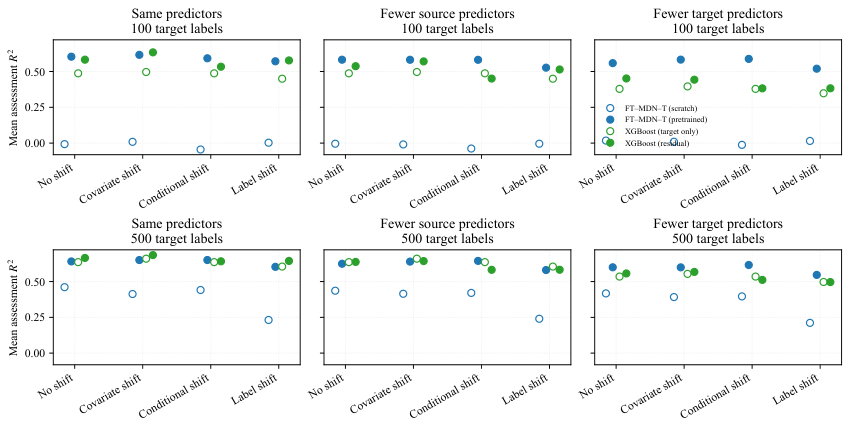

../outputs/simulation_paper/final/augmentation_r2.pdf

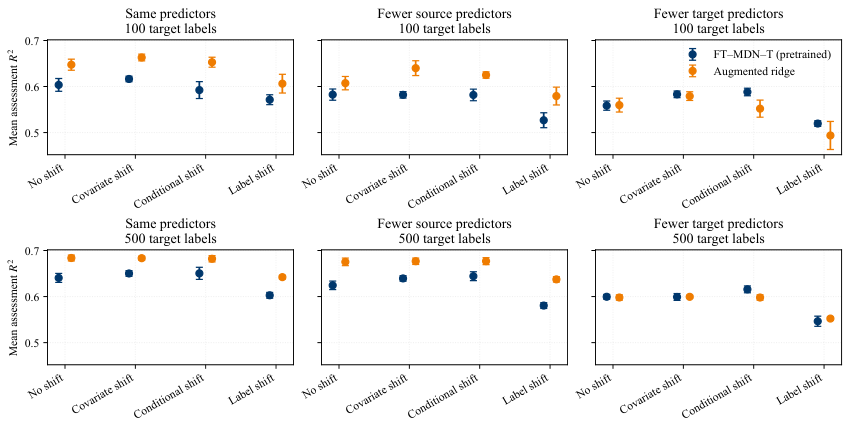

In [41]:
if MODE == "rebuild":
    augmentation_panel(config, primary, final)
keys = ["shift", "schema", "budget", "rep"]
runs = pd.read_csv(final / "replications.csv").merge(
    pd.read_csv(final / "augmentation_runs.csv"), on=keys, validate="one_to_one")
assert len(runs) == 120
runs["FT_minus_augmented_ridge_R2"] = runs.transfer_r2 - runs.augmented_r2
display(runs.groupby(["schema", "budget"]).FT_minus_augmented_ridge_R2.mean().unstack())
means = runs.groupby(["shift","schema","budget"]).mean(numeric_only=True).reset_index()
means["FT_above_both_trees"] = means.transfer_r2 > means[["xgb_scratch_r2","xgb_residual_r2"]].max(axis=1)
means["FT_above_augmented_ridge"] = means.transfer_r2 > means.augmented_r2
display(means.groupby("budget")[["FT_above_both_trees","FT_above_augmented_ridge"]].sum())
display(means.query('schema=="equal" and budget==500 and shift in ["none","label"]')
        [["shift","scratch_r2","transfer_r2","gain_r2"]].round(3))
print("Primary pairs improving on both metrics:", ((runs.gain_r2>0) & (runs.gain_mae>0)).sum(), "/", len(runs))
plot_augmentation(final)
show_figure(final/"absolute_r2.pdf")
show_figure(final/"augmentation_r2.pdf")

Pretrained FT–MDN–T exceeded feature-augmented ridge in mean R² in five conditions. All five had fewer target predictors than source predictors. This finding applies to the predictors omitted in the simulation. The files below give the scores by condition and replication.

In [44]:
for name in ("condition_means.csv","replications.csv","sensitivity_pairs.csv","augmentation_summary.csv","manifest.json"):
    display(FileLink(os.path.relpath(final/name)))
shown = {"paired_gain_r2","training_sensitivity","generator_diagnostics","absolute_r2","augmentation_r2","three_budget_forecasts"}
for path in sorted(final.glob("*.pdf")):
    if path.stem not in shown:
        show_figure(path)

../outputs/simulation_paper/final/condition_means.csv

../outputs/simulation_paper/final/replications.csv

../outputs/simulation_paper/final/sensitivity_pairs.csv

../outputs/simulation_paper/final/augmentation_summary.csv

../outputs/simulation_paper/final/manifest.json

../outputs/simulation_paper/final/paired_gain_mae.pdf

... (2 outputs left out)

../outputs/simulation_paper/final/sample_size_covariate.pdf

../outputs/simulation_paper/final/sample_size_label.pdf

../outputs/simulation_paper/final/sample_size_none.pdf

../outputs/simulation_paper/final/transfer_heatmap.pdf

## 5. Validation results across target sample sizes

This analysis covers five target sample sizes from 100 to 1,000 labels. Scores are available for 222 of 225 planned replication settings. These are validation results. Section 3 reports performance on independent assessment observations.

`review` draws the appendix figures from saved runs. `rebuild` executes the [simulation sweep](archive/simulation_final.ipynb) and writes training output to a log. FT–MDN–T denotes the mixture-density model and FT–Reg the regression-head ablation.

Historical replay | 222/225 planned settings present | 888 model rows
Missing settings: [('conditional', 'equal', 250, 0), ('conditional', 'equal', 250, 1), ('conditional', 'equal', 1000, 0)]
Settings with all four models: 222


,count,mean
budget,,
100,45,0.447
250,43,0.147
500,45,0.041
750,45,0.025
1000,44,0.010


../outputs/simulation_paper/historical/transfer_vs_target_size_reconstruction.pdf

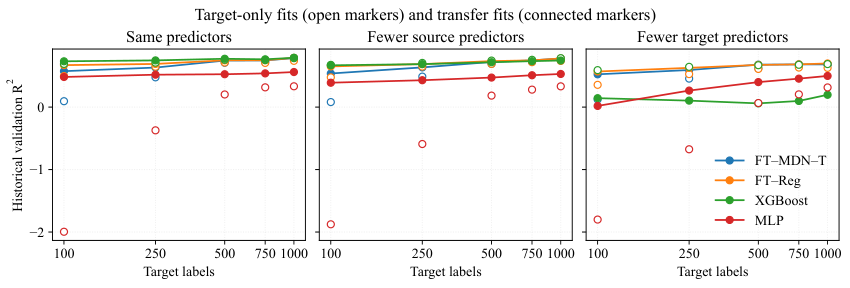

../outputs/simulation_paper/historical/FTMDN_heatmap_headers.pdf

../outputs/simulation_paper/historical/hetero_transfer_violin_highlight.pdf

../outputs/simulation_paper/historical/r2_transfer_by_shift_target100.pdf

../outputs/simulation_paper/historical/r2_transfer_by_shift_target1000.pdf

../outputs/simulation_paper/historical/r2_transfer_by_shift_target500.pdf

../outputs/simulation_paper/historical/r2_transfer_vs_combinedKL_allTargets.pdf

../outputs/simulation_paper/historical/historical_condition_summary.csv

In [49]:
from importlib import reload
from simulation import figure_inventory

if MODE == "rebuild":
    raw_root.mkdir(parents=True,exist_ok=True)
    log = raw_root/"replay_console.log"
    print(f"Validation sweep | 225 planned settings | detailed progress: {log}", flush=True)
    env = dict(os.environ, PYTHONHASHSEED="0", MPLBACKEND="Agg", PYTHONPATH=str(repo/"src"))
    with log.open("a") as stream:
        result = subprocess.run([sys.executable,"-m","simulation.historical_replay",str(repo),str(raw_root)],
                                cwd=repo,env=env,stdout=stream,stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError(f"Validation sweep exited with {result.returncode}. Inspect {log}")
legacy = reload(figure_inventory).plot_historical(repo,raw_root,historical)
index = pd.read_csv(raw_root/"results/index.csv")
raw = pd.concat([pd.read_csv(raw_root/r.raw).assign(shift=r.shift_type,schema=r.hetero,budget=r.target_n)
                 for r in index.itertuples()],ignore_index=True)
observed = set(raw[["shift","schema","budget","simulation_id"]].itertuples(index=False,name=None))
expected = set(product(("covariate","conditional","label"),("equal","target_subset","source_subset"),
                       (100,250,500,750,1000),range(5)))
print(f"Historical replay | {len(observed & expected)}/{len(expected)} planned settings present | {len(raw)} model rows")
print("Missing settings:", sorted(expected-observed))
models_per_setting = raw.groupby(["shift","schema","budget","simulation_id"]).model_name.nunique()
print("Settings with all four models:", models_per_setting.eq(4).sum())
ft = raw.loc[raw.model_name=="FT-MDN"].copy()
ft["validation_R2_gain"] = ft.r2_transfer_learning - ft.r2_target_only
display(ft.groupby("budget").validation_R2_gain.agg(["count","mean"]).round(3))
show_figure(historical/"transfer_vs_target_size_reconstruction.pdf")
for name in legacy:
    if name != "transfer_vs_target_size_reconstruction.pdf":
        show_figure(historical/name)
display(FileLink(os.path.relpath(historical/"historical_condition_summary.csv")))

The mean validation R² gain from pretraining declined from 0.447 at 100 target labels to 0.010 at 1,000. Section 3 examines this sample-size pattern on independent assessment observations and also reports density scores.